# Retail Sales Analysis

Synthetic data for the notebook importer example. No number in this notebook describes a real business.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.io as pio
from IPython.display import SVG, display

pio.renderers.default = 'plotly_mimetype'  # store the figure JSON in the notebook
rng = np.random.default_rng(7)
months = pd.date_range('2025-01-01', periods=18, freq='MS')
revenue = 120 + np.cumsum(rng.normal(2, 6, 18))
sales = pd.DataFrame({'month': months, 'revenue': revenue.round(1)})

## Sales Overview

Monthly revenue in thousand EUR, all stores.

Revenue per month. Hover a point for the exact value.

In [2]:
px.line(sales, x='month', y='revenue', title='Monthly Revenue', labels={'revenue': 'Revenue (k EUR)'})

The last six months as a table.

In [3]:
sales.tail(6).set_index('month')

,revenue
month,
2026-01-01,139.6
2026-02-01,136.0
2026-03-01,137.8
2026-04-01,144.0
2026-05-01,137.9
2026-06-01,137.2


In [4]:
round(float(sales['revenue'].sum()), 1)

2347.7

## Customer Segments

### Segment profiles

Basket size per segment (synthetic).

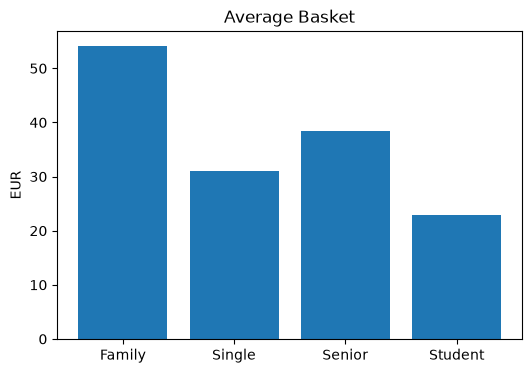

In [5]:
seg = pd.DataFrame({'segment': ['Family', 'Single', 'Senior', 'Student'], 'basket': [54.2, 31.0, 38.5, 22.9]})
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(seg['segment'], seg['basket'])
ax.set(title='Average Basket', ylabel='EUR')
plt.show()

Visits per week and segment.

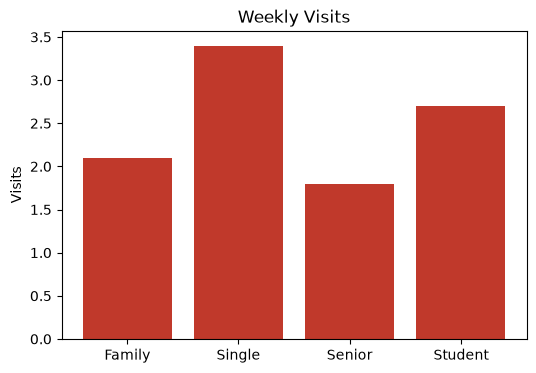

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(seg['segment'], [2.1, 3.4, 1.8, 2.7], color='#c0392b')
ax.set(title='Weekly Visits', ylabel='Visits')
plt.show()

### Loyalty

Share of revenue from loyalty-card holders, as a vector image.

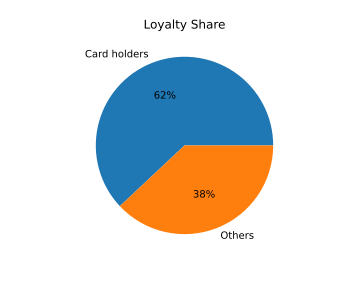

In [7]:
import io
fig, ax = plt.subplots(figsize=(5, 4))
ax.pie([62, 38], labels=['Card holders', 'Others'], autopct='%1.0f%%')
ax.set_title('Loyalty Share')
buf = io.StringIO()
fig.savefig(buf, format='svg')
plt.close(fig)
SVG(buf.getvalue())

## Forecast

**Method.** A linear trend on the last 12 months. It ignores seasonality.

Trend forecast for the next six months (Vega-Lite).

In [8]:
t = np.arange(18)
slope, icpt = np.polyfit(t[-12:], revenue[-12:], 1)
future = pd.date_range(months[-1], periods=7, freq='MS')[1:]
rows = [{'month': str(m.date()), 'revenue': float(v), 'kind': 'actual'} for m, v in zip(months, revenue)]
rows += [{'month': str(m.date()), 'revenue': float(icpt + slope * (18 + i)), 'kind': 'forecast'} for i, m in enumerate(future)]
spec = {'$schema': 'https://vega.github.io/schema/vega-lite/v5.json', 'title': 'Revenue Forecast', 'width': 600, 'height': 300, 'data': {'values': rows}, 'mark': {'type': 'line', 'point': True}, 'encoding': {'x': {'field': 'month', 'type': 'temporal', 'title': 'Month'}, 'y': {'field': 'revenue', 'type': 'quantitative', 'title': 'Revenue (k EUR)'}, 'color': {'field': 'kind', 'type': 'nominal'}}}
display({'application/vnd.vegalite.v5+json': spec}, raw=True)

In [9]:
print('A stream output is not a chart and is not imported.')

A stream output is not a chart and is not imported.
